# IPO Scoring Validation — Explore

Interactive version of `analyze.py` — imports its functions/constants
directly (see the next cell), so the two can never drift out of sync the
way this notebook and `analyze.py` did before rev. 3. Tweak `TARGET`,
columns, or filters below and re-run.

Run with:
```bash
uv run jupyter lab explore.ipynb
```
(`statsmodels`/`scikit-learn`/`matplotlib`/`jupyterlab` are real
`pyproject.toml` dependencies, not `--with` extras — see `README.md`.)

If `ipo_dataset_3yr.csv` is missing or stale, regenerate it first: `uv run fetch_data.py && uv run build_dataset.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess

import analyze as az  # same functions/constants `uv run analyze.py` uses - see its docstring

pd.set_option("display.max_columns", None)
TARGETS = az.TARGETS

/home/monson2002/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/claude-1000/matplotlib-zmlafwml because there was an issue with the default path (/home/monson2002/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## Load & inspect
Tweak the filter below (e.g. by `Sector`, by date range, by `Offer Price` size) and re-run everything below to see how results shift.

In [2]:
df = pd.read_csv("ipo_dataset_3yr.csv", parse_dates=["List Date"])
print(df.shape)
df.head()

(294, 28)


,cg_ipo_id,Name,List Date,Sector,ROE,ROCE,D/E,PAT Margin,P/B,Post IPO P/E,EBITA Margin,GMP,Offer Price,Estimated Price,QIB,bNII,sNII,NII,Retail,Total Sub,% QIB,% Retail,% anchor,Day1 Close,Listing Gain,Ret 6m %,Ret 12m %,Ret 24m %
0,1494,Jupiter Life Line Hospitals Ltd.,2023-09-18,Healthcare,20.03,20.94,NaN,-0.47,NaN,66.10,NaN,NaN,735.0,NaN,181.89,40.64,26.71,36.00,8.00,64.80,50.0,35.0,30.0,1075.75,46.36,53.5,86.5,99.1
1,1503,R R Kabel Ltd.,2023-09-20,Industrials,14.22,15.57,0.36,3.37,NaN,39.26,NaN,NaN,1035.0,NaN,52.26,15.68,8.33,13.23,2.13,18.69,50.0,35.0,30.0,1198.05,15.75,37.9,62.0,21.3
2,1496,EMS Ltd.,2023-09-21,Industrials,22.27,28.26,0.09,20.18,NaN,10.78,NaN,NaN,211.0,NaN,149.98,83.15,86.87,84.39,30.55,76.21,50.0,35.0,30.0,279.90,32.65,86.8,287.2,172.4
3,1502,SAMHI Hotels Ltd.,2023-09-22,Consumer Discretionary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,126.0,NaN,9.18,1.42,1.02,1.29,1.17,5.57,75.0,10.0,45.0,143.40,13.81,64.7,62.9,65.9
4,1505,Zaggle Prepaid Ocean Services Ltd.,2023-09-22,Technology,46.98,NaN,2.48,4.14,NaN,87.23,NaN,NaN,164.0,NaN,16.94,10.36,6.76,9.16,6.15,12.86,75.0,10.0,45.0,158.35,-3.45,79.0,170.3,115.8


In [3]:
df.columns

Index(['cg_ipo_id', 'Name', 'List Date', 'Sector', 'ROE', 'ROCE', 'D/E',
       'PAT Margin', 'P/B', 'Post IPO P/E', 'EBITA Margin', 'GMP',
       'Offer Price', 'Estimated Price', 'QIB', 'bNII', 'sNII', 'NII',
       'Retail', 'Total Sub', '% QIB', '% Retail', '% anchor', 'Day1 Close',
       'Listing Gain', 'Ret 6m %', 'Ret 12m %', 'Ret 24m %'],
      dtype='str')

In [4]:
# missing-value counts per column
df.isna().sum().sort_values(ascending=False)

Ret 24m %          198
Estimated Price    155
GMP                147
Ret 12m %          103
P/B                 53
Ret 6m %            49
EBITA Margin        30
D/E                 28
ROCE                25
ROE                 20
PAT Margin          19
Post IPO P/E        15
NII                 13
Total Sub           13
bNII                13
sNII                13
Retail              13
QIB                 13
Sector               2
Day1 Close           1
% Retail             1
% anchor             1
% QIB                1
List Date            0
Name                 0
cg_ipo_id            0
Offer Price          0
Listing Gain         0
dtype: int64

In [5]:
# optional filter — edit or comment out
# df = df[df["Sector"] == "Technology"]
# df = df[df["List Date"] >= "2024-01-01"]
df.shape

(294, 28)

In [6]:
df = az.add_derived_columns(df)  # GMP %, list_year - see analyze.py

# Notebook-only extras, useful for interactive exploration (not used in
# analyze.py's regressions):
df["Estimated Upside %"] = np.where(
    df["Offer Price"].gt(0),
    (df["Estimated Price"] - df["Offer Price"]) / df["Offer Price"] * 100,
    np.nan,
)
df["list_month"] = df["List Date"].dt.month
df["quarter"] = df["List Date"].dt.quarter

**Note:** `Estimated Upside %` is mathematically identical to `GMP %` in
this dataset, since `Estimated Price = Offer Price + GMP` (verified
r=1.000 — see `analyze.py`'s module docstring). Only `GMP %` is carried
into the correlation/regression sections below; `Estimated Upside %` stays
computed above for reference only.

## Step 1: correlations
Each candidate parameter against every target, individually (pairwise,
drops rows missing that specific column). Reports Spearman rank
correlation alongside Pearson r — a much larger Spearman than Pearson for
the same pair is a nonlinearity signal that Pearson r/an OLS coefficient
alone won't show (see the LOWESS/residual check further down).

In [7]:
CORRELATION_FEATURES = az.FUNDAMENTALS + az.DEMAND_TOTAL + az.DEMAND_CATEGORY + az.ALLOCATION + az.MARKET_SENTIMENT

rows = []
for target in TARGETS:
    corr_df = az.correlations(df, CORRELATION_FEATURES, target)
    corr_df.insert(0, "target", target)
    rows.append(corr_df)

corr_table = pd.concat(rows, ignore_index=True)
corr_table.head(100)

,target,parameter,n,pearson_r,p_value,spearman_r
0,Listing Gain,GMP %,147,0.810151,1.902825e-35,0.821253
1,Listing Gain,Total Sub,281,0.622327,1.600651e-31,0.684368
2,Listing Gain,QIB,281,0.601614,4.731696e-29,0.699501
3,Listing Gain,NII,281,0.486674,4.079781e-18,0.559922
4,Listing Gain,Retail,281,0.417055,2.985404e-13,0.522195
5,Listing Gain,ROCE,269,0.129532,3.370792e-02,0.204079
6,Listing Gain,ROE,274,0.103161,8.831418e-02,0.186883
7,Listing Gain,EBITA Margin,264,-0.056480,3.606817e-01,0.034670
8,Listing Gain,PAT Margin,275,0.053213,3.793755e-01,0.100725
9,Listing Gain,Post IPO P/E,279,-0.048727,4.175210e-01,-0.046076


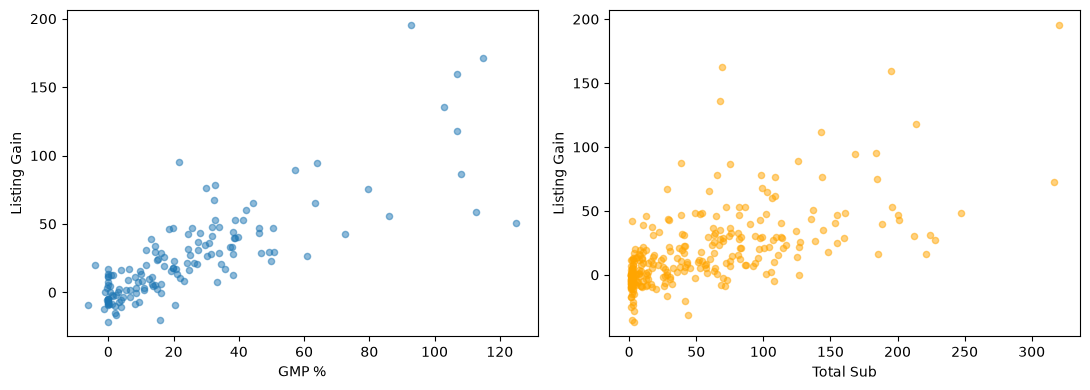

In [8]:
TARGET = TARGETS[0]

# scatter the two strongest, distinct parameters against the target
# (Estimated Upside % is skipped here - it's identical to GMP %, see the
# note above)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df.plot.scatter(x="GMP %", y=TARGET, ax=axes[0], alpha=0.5)
df.plot.scatter(x="Total Sub", y=TARGET, ax=axes[1], alpha=0.5, color="orange")
plt.tight_layout()

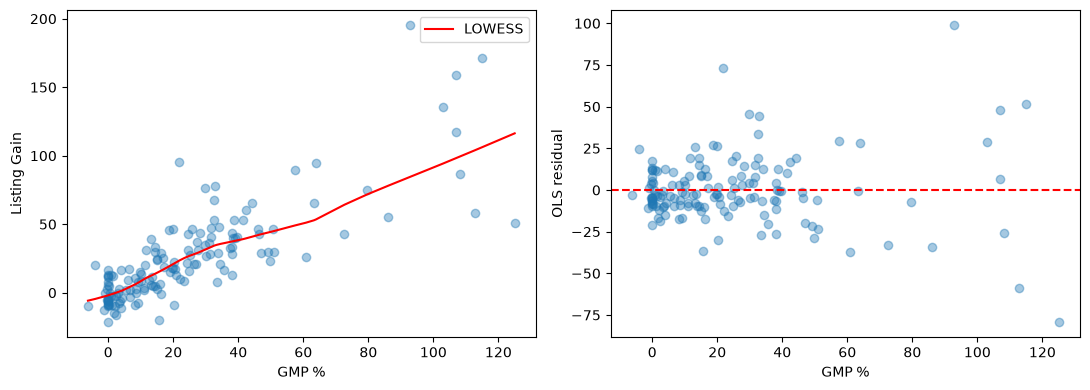

In [9]:
# Nonlinearity check for GMP % vs TARGET: LOWESS overlay + residual plot.
# A strong Pearson r (0.81) doesn't guarantee a linear fit is the right
# functional form - see FINDINGS.md rev. 3.
pair = df[["GMP %", TARGET]].dropna().sort_values("GMP %")
smoothed = lowess(pair[TARGET], pair["GMP %"], frac=0.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(pair["GMP %"], pair[TARGET], alpha=0.4)
axes[0].plot(smoothed[:, 0], smoothed[:, 1], color="red", label="LOWESS")
axes[0].set_xlabel("GMP %"); axes[0].set_ylabel(TARGET); axes[0].legend()

ols_fit = sm.OLS(pair[TARGET], sm.add_constant(pair["GMP %"])).fit()
axes[1].scatter(pair["GMP %"], ols_fit.resid, alpha=0.4)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("GMP %"); axes[1].set_ylabel("OLS residual")
plt.tight_layout()

## Step 2: regression
Z-scored predictors so coefficients are comparable as relative weights.
Every model below calls `analyze.regression()` directly, so it reports the
same thing `uv run analyze.py` prints: in-sample OLS coefficients/p-values,
VIF, and **time-based CV** (`TimeSeriesSplit` on rows sorted by `List
Date` — the primary metric, since a scoring model has to predict future
IPOs from past ones) alongside random 5-fold CV as a secondary benchmark,
both as R²/MAE/RMSE next to a `DummyRegressor(mean)` baseline — never
in-sample R² alone.

In [10]:
cols = az.FUNDAMENTALS + az.DEMAND_TOTAL
subset = df[cols + [TARGET]].dropna()
az.vif_table(subset[cols])  # now includes an explicit constant column - see analyze.py

,parameter,VIF
0,ROE,3.138349
1,ROCE,2.830532
3,PAT Margin,1.661596
4,P/B,1.156696
5,Post IPO P/E,1.115751
2,D/E,1.082962
6,EBITA Margin,1.077642
7,Total Sub,1.071003


In [11]:
az.regression(df, az.FUNDAMENTALS, "Model 1: fundamentals only", TARGET)


--- Model 1: fundamentals only -> Listing Gain (n=202 complete rows) ---
in-sample R^2 = 0.022, adj R^2 = -0.013


  [time-based, primary] model: R^2=-1.528 (range=[-4.130, -0.154]), MAE=26.99, RMSE=36.42
  [time-based, primary] baseline (predict mean): R^2=-0.539 (range=[-1.899, -0.001]), MAE=23.30, RMSE=29.07
  [random 5-fold, secondary] model: R^2=-0.166 (range=[-0.618, 0.024]), MAE=23.42, RMSE=33.68
  [random 5-fold, secondary] baseline (predict mean): R^2=-0.013 (range=[-0.025, -0.001]), MAE=22.26, RMSE=31.86
               coef  std_err      t  p_value  ci_low  ci_high  significant_p<0.05
ROE           1.320    3.962  0.333    0.739  -6.494    9.134               False
ROCE          2.589    3.805  0.680    0.497  -4.915   10.093               False
D/E           1.836    2.376  0.773    0.441  -2.850    6.522               False
PAT Margin    0.498    2.882  0.173    0.863  -5.187    6.183               False
P/B          -0.881    2.443 -0.361    0.719  -5.700    3.938               False
Post IPO P/E -0.448    2.415 -0.186    0.853  -5.211    4.314               False
EBITA Margin -1.817  

In [12]:
az.regression(df, az.FUNDAMENTALS + az.DEMAND_TOTAL, "Model 2: fundamentals + Total Sub (no GMP)", TARGET)
az.regression(df, az.FUNDAMENTALS + az.MARKET_SENTIMENT, "Model 3: fundamentals + GMP % (no Total Sub)", TARGET)
az.regression(df, az.FUNDAMENTALS + az.DEMAND_TOTAL + az.MARKET_SENTIMENT, "Model 4: fundamentals + Total Sub + GMP %", TARGET)
az.regression(df, az.FUNDAMENTALS + az.DEMAND_CATEGORY, "Model 5: fundamentals + QIB/NII/Retail (no GMP)", TARGET)


--- Model 2: fundamentals + Total Sub (no GMP) -> Listing Gain (n=194 complete rows) ---
in-sample R^2 = 0.459, adj R^2 = 0.435
  [time-based, primary] model: R^2=-0.167 (range=[-0.589, 0.251]), MAE=20.15, RMSE=27.01
  [time-based, primary] baseline (predict mean): R^2=-0.474 (range=[-1.663, -0.023]), MAE=22.86, RMSE=28.77
  [random 5-fold, secondary] model: R^2=0.155 (range=[-0.638, 0.660]), MAE=17.02, RMSE=24.91
  [random 5-fold, secondary] baseline (predict mean): R^2=-0.039 (range=[-0.089, -0.008]), MAE=21.41, RMSE=29.50
                coef  std_err       t  p_value  ci_low  ci_high  significant_p<0.05
ROE           -3.343    2.934  -1.139    0.256  -9.132    2.445               False
ROCE           2.123    2.787   0.762    0.447  -3.375    7.620               False
D/E            0.963    1.724   0.558    0.577  -2.438    4.363               False
PAT Margin     1.235    2.135   0.579    0.564  -2.977    5.447               False
P/B            2.192    1.781   1.231    0.220  

  [random 5-fold, secondary] model: R^2=0.327 (range=[-0.782, 0.688]), MAE=15.89, RMSE=25.57
  [random 5-fold, secondary] baseline (predict mean): R^2=-0.037 (range=[-0.149, -0.000]), MAE=23.93, RMSE=33.43
                coef  std_err      t  p_value  ci_low  ci_high  significant_p<0.05
ROE           -6.610    3.216 -2.055    0.042 -12.983   -0.238                True
ROCE           3.280    3.031  1.082    0.281  -2.724    9.284               False
D/E            1.004    1.798  0.559    0.577  -2.557    4.566               False
PAT Margin     0.055    2.300  0.024    0.981  -4.502    4.612               False
P/B            2.680    1.861  1.440    0.153  -1.007    6.367               False
Post IPO P/E   0.169    1.841  0.092    0.927  -3.478    3.817               False
EBITA Margin   0.833    1.777  0.469    0.640  -2.688    4.354               False
Total Sub      7.737    2.447  3.162    0.002   2.888   12.585                True
GMP %         23.770    2.407  9.875    0.000  

## Step 3: matched-sample, missingness, and regularization checks
Same reuse principle as above — these call the exact functions
`analyze.py` runs for every target, restricted here to `TARGET`.

In [13]:
az.matched_sample_comparison(df, TARGET)
az.gmp_missingness_check(df)

# Model 3 beat Model 4 under both CV metrics above - check regularization
# against it too, not just Model 4, before treating either as the leading spec.
az.compare_regularization(df, az.FUNDAMENTALS + az.MARKET_SENTIMENT, "Model 3", TARGET)

matched_idx = df[az.FUNDAMENTALS + az.DEMAND_TOTAL + az.MARKET_SENTIMENT + [TARGET]].dropna().index
az.compare_regularization(df, az.FUNDAMENTALS + az.DEMAND_TOTAL + az.MARKET_SENTIMENT, "Model 4, matched sample", TARGET, restrict_index=matched_idx)

az.robustness_sweep(df, TARGET)


=== Matched-sample comparison (n=123, identical rows both specs) ===



--- Matched sample: Model A, no GMP % -> Listing Gain (n=123 complete rows) ---
in-sample R^2 = 0.472, adj R^2 = 0.435
  [time-based, primary] model: R^2=-0.237 (range=[-0.599, 0.172]), MAE=22.35, RMSE=30.19
  [time-based, primary] baseline (predict mean): R^2=-0.603 (range=[-2.640, -0.018]), MAE=23.68, RMSE=31.55
  [random 5-fold, secondary] model: R^2=-0.486 (range=[-3.286, 0.668]), MAE=21.51, RMSE=36.24
  [random 5-fold, secondary] baseline (predict mean): R^2=-0.037 (range=[-0.149, -0.000]), MAE=23.93, RMSE=33.43
                coef  std_err      t  p_value  ci_low  ci_high  significant_p<0.05
ROE           -5.889    4.370 -1.348    0.180 -14.546    2.767               False
ROCE           3.921    4.117  0.952    0.343  -4.236   12.077               False
D/E            1.751    2.441  0.717    0.475  -3.085    6.586               False
PAT Margin     0.863    3.124  0.276    0.783  -5.326    7.051               False
P/B            3.135    2.528  1.240    0.217  -1.873    8.14

  Sector x GMP-availability: chi2 p=0.6804

=== Regularization comparison: Model 3 -> Listing Gain (n=131) ===
  OLS: time-based CV R^2=0.190, MAE=15.85, RMSE=21.24
  RidgeCV: time-based CV R^2=0.499, MAE=12.82, RMSE=17.05 (alpha per fold: [10.0, 10.0, 5.6234, 5.6234, 10.0])


  ElasticNetCV: time-based CV R^2=0.506, MAE=12.45, RMSE=16.85 (alpha, l1_ratio per fold: [(1.7783, 0.3), (0.1778, 0.3), (3.1623, 1.0), (0.3162, 0.95), (1.7783, 1.0)])

=== Regularization comparison: Model 4, matched sample -> Listing Gain (n=123) ===
  OLS: time-based CV R^2=0.150, MAE=17.69, RMSE=22.94
  RidgeCV: time-based CV R^2=0.464, MAE=14.50, RMSE=18.97 (alpha per fold: [10.0, 10.0, 10.0, 10.0, 17.7828])


  ElasticNetCV: time-based CV R^2=0.522, MAE=13.95, RMSE=18.43 (alpha, l1_ratio per fold: [(1.0, 0.1), (0.3162, 0.1), (0.3162, 0.1), (1.7783, 1.0), (3.1623, 1.0)])

ROBUSTNESS SWEEP: Model 3's GMP % relationship -> Listing Gain (n=131)
(market regime not checked - no market-index data in this dataset)

-- by year --
  2024: n=85, pearson_r=0.820, GMP% slope=1.035 (p=0.0000)
  2025: n=33, pearson_r=0.866, GMP% slope=1.117 (p=0.0000)
  2026: n=13, too few rows

-- by sector --
  Consumer Discretionary: n=18, pearson_r=0.742, GMP% slope=0.559 (p=0.0004)
  Energy: n=19, pearson_r=0.861, GMP% slope=0.857 (p=0.0000)
  Financials: n=13, too few rows
  Healthcare: n=14, too few rows
  Industrials: n=22, pearson_r=0.875, GMP% slope=1.151 (p=0.0000)
  Materials: n=9, too few rows
  Other: n=24, pearson_r=0.854, GMP% slope=0.999 (p=0.0000)
  Real Estate: n=3, too few rows
  Technology: n=8, too few rows

-- by IPO size (Offer Price tercile, no total-issue-size column available) --
  small: n=44, 

## Ideas to try from here

- Swap `TARGET` (in the scatter cell above) for `Ret 6m %` / `Ret 12m %` /
  `Ret 24m %` and re-run everything below it — does fundamentals'
  correlation improve on a longer horizon than listing-day gain? (see
  `FINDINGS.md` rev. 3 for the current answer)
- Cross-check individual outlier rows (e.g. `df.sort_values("Listing Gain").head()`)
  against `crosscheck_report.csv` if they overlap the Sep–Nov 2023 window.
- The robustness sweep `FINDINGS.md` rev. 3 explicitly defers (performance
  by time period / sector / IPO size / market regime) is a good next thing
  to explore interactively here, cell by cell, before it's worth
  scripting into `analyze.py`.